In [1]:
# Cell 1
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal as mvn
from scipy.optimize import minimize
from scipy.special import expit   

SEED = 3                           
rng = np.random.default_rng(SEED)

In [2]:
PRIORS = np.array([0.6, 0.4])
W_MIX  = [0.5, 0.5]
MEANS  = {0: [np.array([-0.9, -1.1]), np.array([0.8, 0.75])],
          1: [np.array([-1.1,  0.9]), np.array([0.9, -0.75])]}
COV  = np.array([[0.75, 0.0], [0.0, 1.25]])
CHOL = np.linalg.cholesky(COV)

def generate_data(N, rng):
    labels = (rng.random(N) >= PRIORS[0]).astype(int) 
    comp   = (rng.random(N) >= W_MIX[0]).astype(int)  
    X = np.zeros((N, 2))
    for l in (0, 1):
        for c in (0, 1):
            idx = (labels == l) & (comp == c)
            X[idx] = MEANS[l][c] + rng.standard_normal((idx.sum(), 2)) @ CHOL.T
    return X, labels

sizes = {"D20_train": 20, "D200_train": 200, "D2000_train": 2000, "D10K_validate": 10000}
data = {name: generate_data(N, rng) for name, N in sizes.items()}

for name, (X, L) in data.items():
    print(f"{name:14s}: N = {len(L):5d} | class 0: {np.sum(L==0):5d} | class 1: {np.sum(L==1):5d}")

D20_train     : N =    20 | class 0:    14 | class 1:     6
D200_train    : N =   200 | class 0:   119 | class 1:    81
D2000_train   : N =  2000 | class 0:  1197 | class 1:   803
D10K_validate : N = 10000 | class 0:  6012 | class 1:  3988


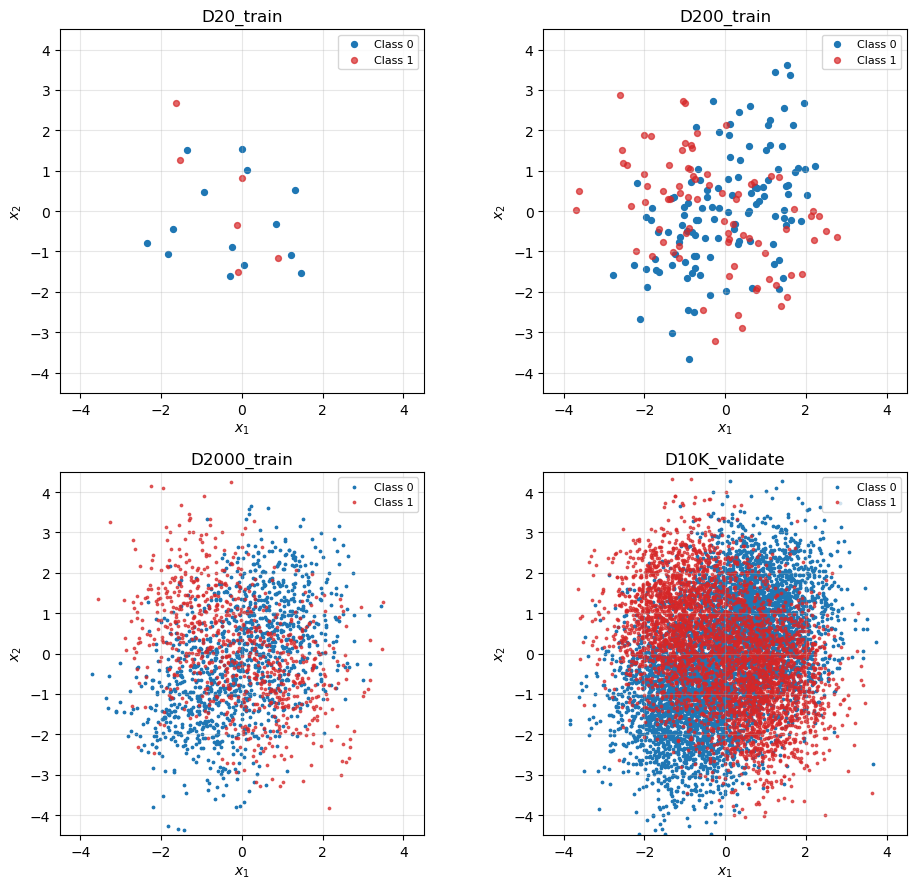

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, (X, L)) in zip(axes.ravel(), data.items()):
    ms = 18 if len(L) <= 200 else 3
    ax.scatter(*X[L==0].T, s=ms, c="tab:blue", label="Class 0")
    ax.scatter(*X[L==1].T, s=ms, c="tab:red",  label="Class 1", alpha=0.7)
    ax.set_title(name); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
def class_likelihood(X, l):
    return sum(w * mvn.pdf(X, m, COV) for w, m in zip(W_MIX, MEANS[l]))

def log_likelihood_ratio(X):
    return np.log(class_likelihood(X, 1)) - np.log(class_likelihood(X, 0))

def confusion(dec, L):
    # rows = true label, columns = decision
    return np.array([[np.sum((L == i) & (dec == j)) for j in (0, 1)] for i in (0, 1)])

def report(title, dec, L):
    cm = confusion(dec, L)
    perr = np.mean(dec != L)
    tpr, fpr = cm[1, 1] / cm[1].sum(), cm[0, 1] / cm[0].sum()
    print(f"--- {title} ---")
    print(f"P(error) = {perr:.4f}  ({cm[0,1] + cm[1,0]} errors out of {len(L)})")
    print(f"                 Decide 0   Decide 1")
    print(f"True L=0:      {cm[0,0]:8d}   {cm[0,1]:8d}")
    print(f"True L=1:      {cm[1,0]:8d}   {cm[1,1]:8d}")
    print(f"TPR = P(D=1|L=1) = {tpr:.4f},  FPR = P(D=1|L=0) = {fpr:.4f}\n")
    return perr, tpr, fpr

Xv, Lv = data["D10K_validate"]
score_v = log_likelihood_ratio(Xv)
tau_star = np.log(PRIORS[0] / PRIORS[1])
dec_opt = (score_v > tau_star).astype(int)
perr_opt, tpr_opt, fpr_opt = report("Theoretically optimal classifier on D10K_validate", dec_opt, Lv)

--- Theoretically optimal classifier on D10K_validate ---
P(error) = 0.2772  (2772 errors out of 10000)
                 Decide 0   Decide 1
True L=0:          5073        939
True L=1:          1833       2155
TPR = P(D=1|L=1) = 0.5404,  FPR = P(D=1|L=0) = 0.1562



Theoretical threshold tau* = ln(1.5) = 0.4055  ->  P(error) = 0.2772
Empirically best threshold on this set = 0.5563  ->  P(error) = 0.2744


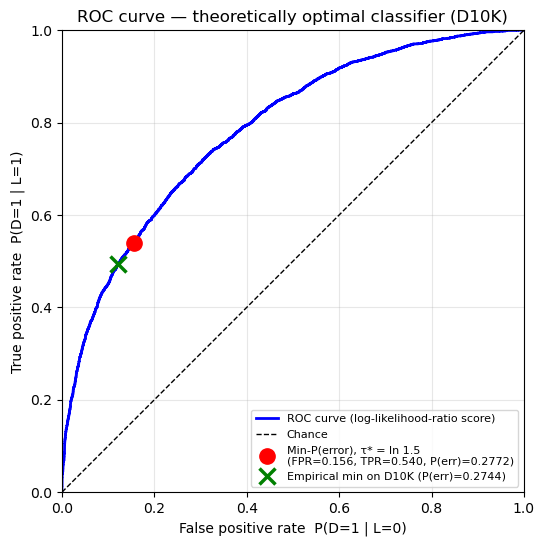

In [5]:
def roc_curve(score, L):
    order = np.argsort(-score)
    s_sorted, L_sorted = score[order], L[order]
    tp = np.concatenate(([0], np.cumsum(L_sorted == 1)))
    fp = np.concatenate(([0], np.cumsum(L_sorted == 0)))
    tpr, fpr = tp / np.sum(L == 1), fp / np.sum(L == 0)
    thresholds = np.concatenate(([np.inf], s_sorted))
    return fpr, tpr, thresholds

fpr_c, tpr_c, thr_c = roc_curve(score_v, Lv)
N0, N1 = np.sum(Lv == 0), np.sum(Lv == 1)
perr_curve = fpr_c * N0 / len(Lv) + (1 - tpr_c) * N1 / len(Lv)
k = np.argmin(perr_curve)
print(f"Theoretical threshold tau* = ln(1.5) = {tau_star:.4f}  ->  P(error) = {perr_opt:.4f}")
print(f"Empirically best threshold on this set = {thr_c[k]:.4f}  ->  P(error) = {perr_curve[k]:.4f}")

plt.figure(figsize=(6.5, 6))
plt.plot(fpr_c, tpr_c, "b-", lw=2, label="ROC curve (log-likelihood-ratio score)")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
plt.plot(fpr_opt, tpr_opt, "ro", ms=11,
         label=f"Min-P(error), τ* = ln 1.5\n(FPR={fpr_opt:.3f}, TPR={tpr_opt:.3f}, P(err)={perr_opt:.4f})")
plt.plot(fpr_c[k], tpr_c[k], "gx", ms=11, mew=2.5,
         label=f"Empirical min on D10K (P(err)={perr_curve[k]:.4f})")
plt.xlabel("False positive rate  P(D=1 | L=0)"); plt.ylabel("True positive rate  P(D=1 | L=1)")
plt.title("ROC curve — theoretically optimal classifier (D10K)")
plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=0.3); plt.axis("square"); plt.xlim(0, 1); plt.ylim(0, 1)
plt.show()

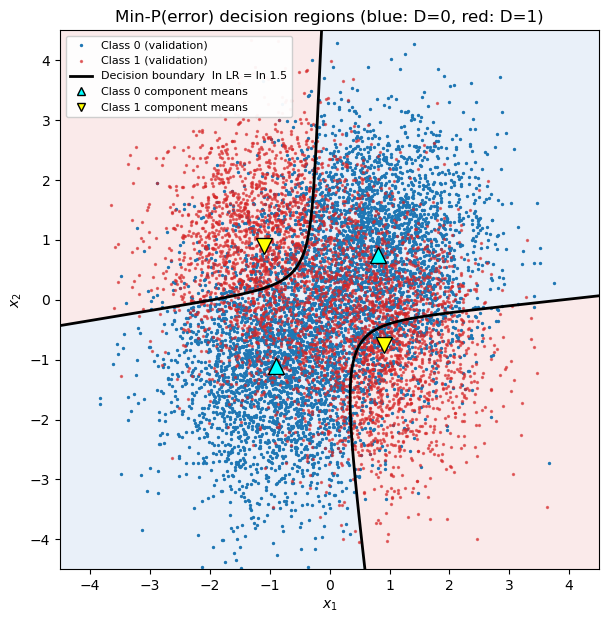

In [6]:
g1, g2 = np.meshgrid(np.linspace(-4.5, 4.5, 400), np.linspace(-4.5, 4.5, 400))
grid = np.column_stack([g1.ravel(), g2.ravel()])
llr_grid = log_likelihood_ratio(grid).reshape(g1.shape)

plt.figure(figsize=(7, 7))
plt.contourf(g1, g2, llr_grid > tau_star, levels=[-0.5, 0.5, 1.5], colors=["#dbe7f5", "#f7dcdc"], alpha=0.6)
plt.scatter(*Xv[Lv==0].T, s=2, c="tab:blue", label="Class 0 (validation)")
plt.scatter(*Xv[Lv==1].T, s=2, c="tab:red", alpha=0.6, label="Class 1 (validation)")
plt.contour(g1, g2, llr_grid, levels=[tau_star], colors="k", linewidths=2)
for l, mk in ((0, "^"), (1, "v")):
    for m in MEANS[l]:
        plt.plot(*m, mk, ms=12, mec="k", mfc="yellow" if l else "cyan")
plt.plot([], [], "k-", lw=2, label="Decision boundary  ln LR = ln 1.5")
plt.plot([], [], "^", mec="k", mfc="cyan", label="Class 0 component means")
plt.plot([], [], "v", mec="k", mfc="yellow", label="Class 1 component means")
plt.xlim(-4.5, 4.5); plt.ylim(-4.5, 4.5)
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title("Min-P(error) decision regions (blue: D=0, red: D=1)")
plt.legend(loc="upper left", fontsize=8, framealpha=0.95); plt.gca().set_aspect("equal"); plt.show()

In [7]:
def z_linear(X):
    return np.column_stack([np.ones(len(X)), X[:, 0], X[:, 1]])

def z_quadratic(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([np.ones(len(X)), x1, x2, x1**2, x1 * x2, x2**2])

def nll(w, Z, y):
    a = Z @ w
    return np.mean(np.logaddexp(0, a) - y * a)

def nll_grad(w, Z, y):
    return Z.T @ (expit(Z @ w) - y) / len(y)

def fit_logistic(Z, y):
    res = minimize(nll, np.zeros(Z.shape[1]), args=(Z, y), jac=nll_grad,
                   method="BFGS", options={"gtol": 1e-8, "maxiter": 20000})
    return res

models = {"Linear": z_linear, "Quadratic": z_quadratic}
train_sets = ["D20_train", "D200_train", "D2000_train"]
results = {}

for mname, zf in models.items():
    for dname in train_sets:
        X, L = data[dname]
        res = fit_logistic(zf(X), L)
        w = res.x
        dec_val = (zf(Xv) @ w >= 0).astype(int)
        dec_tr  = (zf(X)  @ w >= 0).astype(int)
        print(f"[{mname} | {dname}]  optimizer converged: {res.success},  final NLL = {res.fun:.4f}")
        print("   w_hat =", np.round(w, 3))
        perr, _, _ = report(f"{mname} logistic, trained on {dname}, evaluated on D10K_validate", dec_val, Lv)
        results[(mname, dname)] = dict(w=w, perr_val=perr, perr_train=np.mean(dec_tr != L))

[Linear | D20_train]  optimizer converged: True,  final NLL = 0.5880
   w_hat = [-0.843  0.004  0.381]
--- Linear logistic, trained on D20_train, evaluated on D10K_validate ---
P(error) = 0.4062  (4062 errors out of 10000)
                 Decide 0   Decide 1
True L=0:          5684        328
True L=1:          3734        254
TPR = P(D=1|L=1) = 0.0637,  FPR = P(D=1|L=0) = 0.0546

[Linear | D200_train]  optimizer converged: True,  final NLL = 0.6674
   w_hat = [-0.417 -0.192  0.003]
--- Linear logistic, trained on D200_train, evaluated on D10K_validate ---
P(error) = 0.4002  (4002 errors out of 10000)
                 Decide 0   Decide 1
True L=0:          5802        210
True L=1:          3792        196
TPR = P(D=1|L=1) = 0.0491,  FPR = P(D=1|L=0) = 0.0349

[Linear | D2000_train]  optimizer converged: True,  final NLL = 0.6678
   w_hat = [-0.406 -0.083  0.142]
--- Linear logistic, trained on D2000_train, evaluated on D10K_validate ---
P(error) = 0.3781  (3781 errors out of 10000)
 

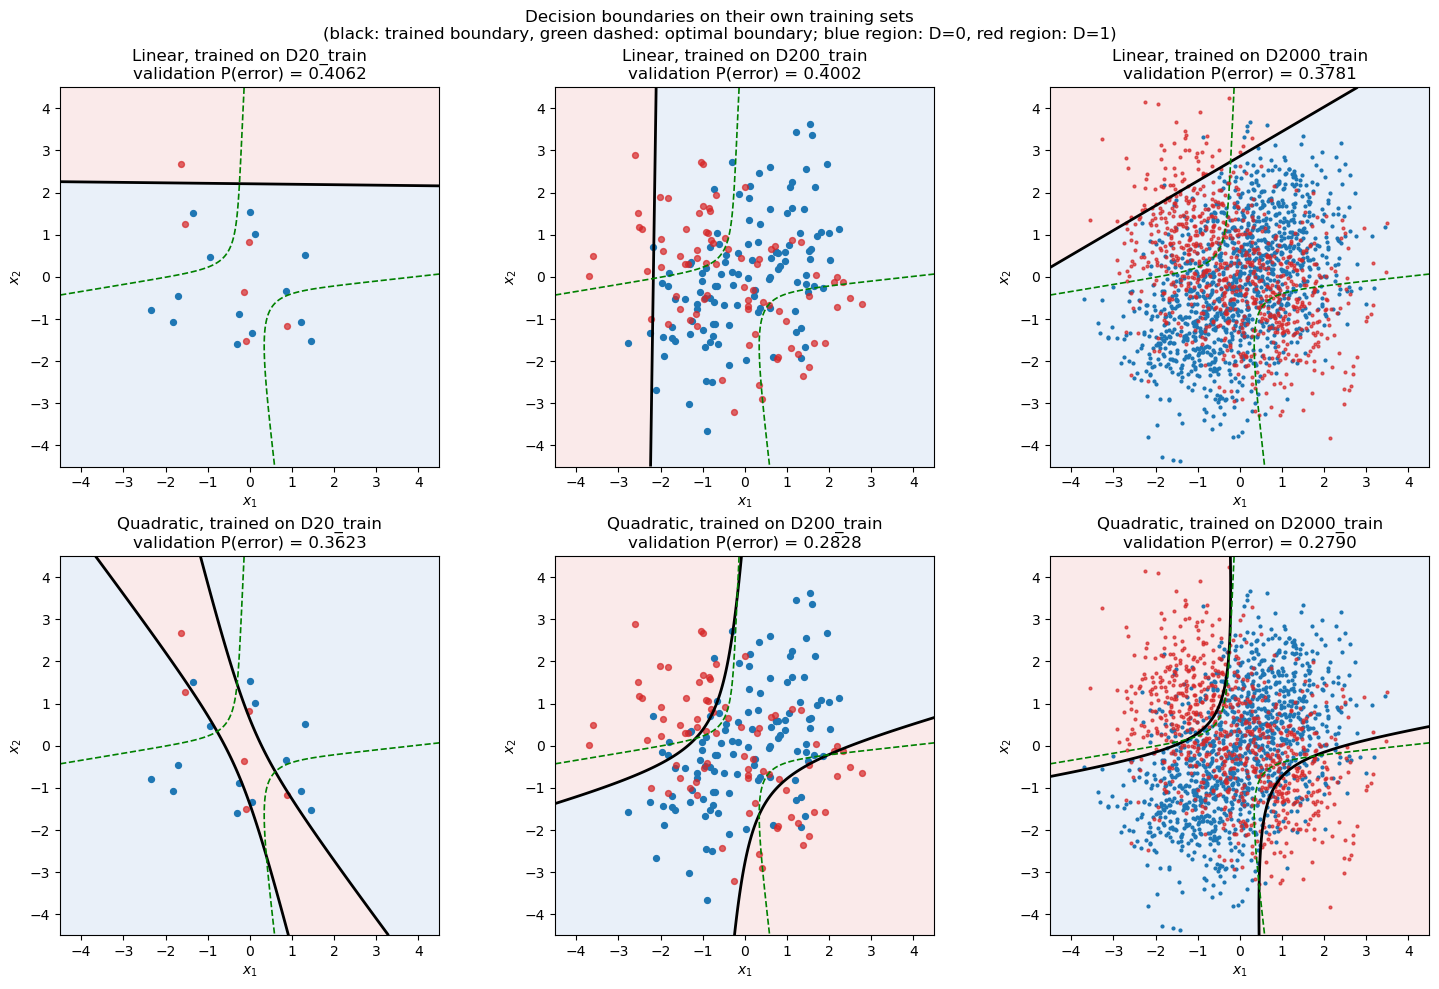

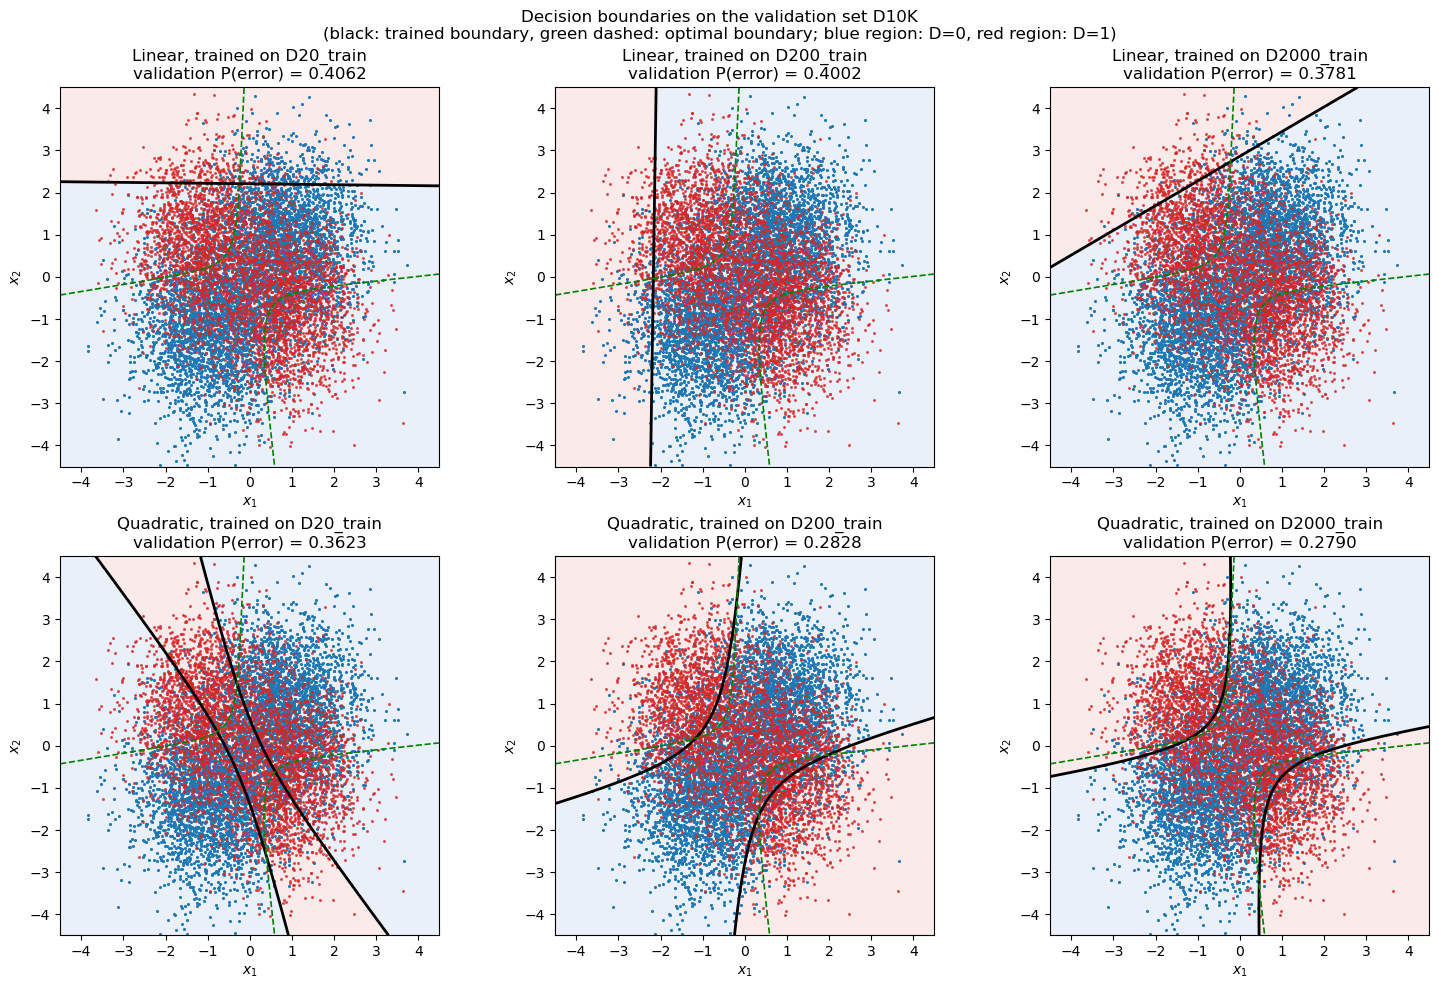

In [8]:
def plot_boundaries(points_from, suptitle):
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    for r, (mname, zf) in enumerate(models.items()):
        Zg = zf(grid)
        for c, dname in enumerate(train_sets):
            ax = axes[r, c]
            w = results[(mname, dname)]["w"]
            a_grid = (Zg @ w).reshape(g1.shape)
            X, L = data[points_from if points_from else dname]
            ms = 18 if len(L) <= 200 else (4 if len(L) <= 2000 else 1.5)
            ax.contourf(g1, g2, a_grid >= 0, levels=[-0.5, 0.5, 1.5], colors=["#dbe7f5", "#f7dcdc"], alpha=0.6)
            ax.scatter(*X[L==0].T, s=ms, c="tab:blue")
            ax.scatter(*X[L==1].T, s=ms, c="tab:red", alpha=0.7)
            ax.contour(g1, g2, a_grid, levels=[0], colors="k", linewidths=2)
            ax.contour(g1, g2, llr_grid, levels=[tau_star], colors="g", linewidths=1.2, linestyles="--")
            ax.set_title(f"{mname}, trained on {dname}\nvalidation P(error) = {results[(mname, dname)]['perr_val']:.4f}")
            ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect("equal")
            ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    fig.suptitle(suptitle + "\n(black: trained boundary, green dashed: optimal boundary; "
                 "blue region: D=0, red region: D=1)", fontsize=12)
    plt.tight_layout(); plt.show()

plot_boundaries(None, "Decision boundaries on their own training sets")
plot_boundaries("D10K_validate", "Decision boundaries on the validation set D10K")

In [9]:
print(f"{'Classifier':32s}{'Train P(error)':>16s}{'Val P(error)':>14s}{'Gap to optimal':>16s}")
print(f"{'Theoretically optimal (Part 1)':32s}{'—':>16s}{perr_opt:14.4f}{'—':>16s}")
for (mname, dname), r in results.items():
    print(f"{mname + ' / ' + dname:32s}{r['perr_train']:16.4f}{r['perr_val']:14.4f}{r['perr_val'] - perr_opt:+16.4f}")

Classifier                        Train P(error)  Val P(error)  Gap to optimal
Theoretically optimal (Part 1)                 —        0.2772               —
Linear / D20_train                        0.2500        0.4062         +0.1290
Linear / D200_train                       0.3850        0.4002         +0.1230
Linear / D2000_train                      0.3755        0.3781         +0.1009
Quadratic / D20_train                     0.2500        0.3623         +0.0851
Quadratic / D200_train                    0.2650        0.2828         +0.0056
Quadratic / D2000_train                   0.2830        0.2790         +0.0018
